# 2. Network construction

**Network.** Nodes are the organisations that took part in at least one Horizon Europe project. Two organisations are linked if they took part in at least one project together. While the data collected describe a bipartite network, with organisations and projects as nodes and participations as links between them, the network built here is its projection onto organisations, where projects are replaced by direct links among their participants.

**Node attributes.** From `organization.csv`: name, country, activity type. Computed over the organisation's participations: number of projects, number of projects coordinated, and whether the organisation is isolated.

**Edge attributes.** `weight` = number of projects in common.

**Construction rules.**
- *Nodes.* One per `organisationID`. Participations without identifier are excluded, since they cannot be assigned to a node (none in this snapshot).
- *Participations.* Every organisation–project pair counts once. Duplicate records of the same pair are merged: coordinator role kept if either record has it.
- *Roles.* All four roles recorded by CORDIS (coordinator, participant, associated partner, third party) count as participations, since all of them take part in the project work. The coordinator role is kept as a node attribute.
- *Projects.* All the projects of the snapshot are used, whatever their status and start date. An edge therefore records that two organisations are part of the same grant agreement, including projects that have not started yet at the snapshot date.
- *Terminated participations.* Kept, since the organisation was part of the consortium.
- *Single-participant projects.* They generate no edges. Their organisations remain in the network as isolated nodes, since they are part of the funding landscape.

## Imports and configuration

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# Snapshot of the tables produced by 01_data_collection.ipynb
SNAPSHOT_DIR = Path("../data/snapshot")
# Output folder for the network
NET_DIR = Path("../data/network")
# Output folder for the cleaned participations
PART_DIR = Path("../data/participations")
# Output folder for the figures
FIG_DIR = Path("../figures")

NET_DIR.mkdir(parents=True, exist_ok=True)
PART_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Loading and cleaning

### Loading the tables

We load the two tables produced in `01_data_collection.ipynb`, from the snapshot kept in `data/snapshot/`: the participations, which define the edges, and the projects, which provide the start dates.

In [2]:
# Load the participations: one row per organisation-project pair
participations = pd.read_csv(SNAPSHOT_DIR / "organization.csv.gz", sep=";", low_memory=False,
                             keep_default_na=False, na_values=[""])

# Load the projects, keeping only the identifier and the start date
projects = pd.read_csv(SNAPSHOT_DIR / "project_json.csv.gz", usecols=["id", "startDate"])

# Start year of each project, taken from the first 4 characters of the date
projects["startYear"] = projects["startDate"].str[:4].astype("Int64")

print("participations:", len(participations))
print("projects:      ", len(projects))

participations: 145909
projects:       23613


### Cleaning the participations

Before building the network, we perform three checks on the participations. We remove those without organisation identifier, which cannot be assigned to a node. We then look for duplicate organisation–project pairs, i.e. organisations recorded twice in the same project, and keep one record per pair. The role is the only attribute of a participation kept in the network, so we count the pairs whose two records carry different roles, and we preserve the coordinator role before the removal: the pair is marked as coordinator if either record is. Finally, we verify that every participation refers to a project present in the project table.

In [3]:
# Participations without organisation identifier are removed, since they cannot be assigned to a node
no_id = participations["organisationID"].isna()
participations = participations[~no_id].copy()
participations["organisationID"] = participations["organisationID"].astype(int)

# Duplicate organisation-project pairs, and how many of them are recorded with two different roles
pair = ["projectID", "organisationID"]
dup = participations[participations.duplicated(subset=pair, keep=False)]
two_roles = dup.groupby(pair)["role"].nunique().gt(1).sum()

# One record is kept per pair. The pair counts as coordinator if either record is
participations["is_coordinator"] = participations.groupby(pair)["role"].transform(lambda s: (s == "coordinator").any())
participations = participations.drop_duplicates(subset=pair)

# Every participation must refer to a project present in the project table
unknown = ~participations["projectID"].isin(projects["id"])

# Summary of the cleaning
print("Cleaning summary:")
print(f"  removed, no organisationID:   {no_id.sum():>7}")
print(f"  removed, duplicated pairs:    {len(dup) // 2:>7}")
print(f"  of which with two roles:      {two_roles:>7}")
print(f"  unknown project:              {unknown.sum():>7}")
print(f"  clean participations:         {len(participations):>7}")
print(f"  organisations:                {participations['organisationID'].nunique():>7}")
print(f"  projects:                     {participations['projectID'].nunique():>7}")

Cleaning summary:
  removed, no organisationID:         0
  removed, duplicated pairs:        278
  of which with two roles:          230
  unknown project:                    0
  clean participations:          145631
  organisations:                  35200
  projects:                       23613


## Data characterization

Before turning the participations into a network, we describe how they are distributed: across projects, across organisations, across countries and activity types, by role, over time, and how complete the node attributes are.

### Participants per project

Each project with $n$ participants generates $\binom{n}{2}$ edges, one for every pair of participants. The distribution of the number of participants therefore determines the number of edges.

In [4]:
# Number of participants of each project
participants = participations.groupby("projectID").size()

# Number of edges each project generates, one for every pair of participants
edges_per_project = participants * (participants - 1) // 2

# Share of the edges generated by the 1% of projects with most participants
largest_1pct = edges_per_project.sort_values(ascending=False).head(len(edges_per_project) // 100)
share_1pct = largest_1pct.sum() / edges_per_project.sum()

print("Participants per project:")
print(f"  projects with a single participant:   {(participants == 1).sum():>7}  ({(participants == 1).mean():.1%})")
print(f"  median participants per project:      {participants.median():>7.0f}")
print(f"  maximum participants in a project:    {participants.max():>7}")
print(f"  pairs generated by the projects:      {edges_per_project.sum():>7}")
print(f"  share generated by the largest 1%:    {share_1pct:>7.1%}")

Participants per project:
  projects with a single participant:     11072  (46.9%)
  median participants per project:            2
  maximum participants in a project:        199
  pairs generated by the projects:      1335249
  share generated by the largest 1%:      30.4%


Almost half of the projects (46.9%) have a single participant and generate no edges, which brings the median down to two. The largest project has 199 participants, and the 1% of projects with most participants generate 30% of the pairs.

The history saving thread hit an unexpected error (OperationalError('database is locked')).History will not be written to the database.


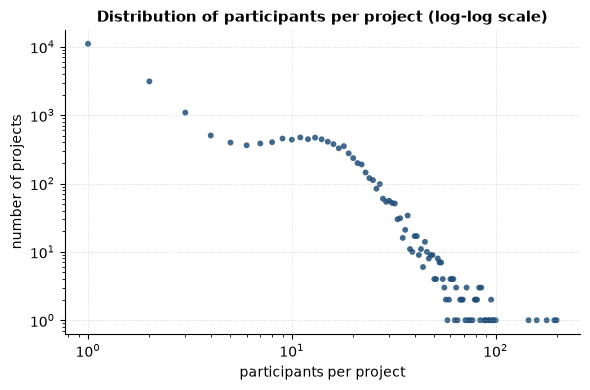

In [5]:
# Distribution of the number of participants per project (log-log scale)
counts = participants.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(counts.index, counts.values, s=18, color="#1f4e79", alpha=0.85, edgecolor="none")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("participants per project")
ax.set_ylabel("number of projects")
ax.set_title("Distribution of participants per project (log-log scale)", fontsize=11, fontweight="bold")
ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "participants_per_project.png", dpi=200)
plt.show()

On log-log axes the distribution is not a straight line, so it does not appear to follow a power law: after a sharp drop from single-participant projects, it stays roughly flat for projects with a moderate number of participants and then decays quickly for the largest ones.

### Projects per organisation

We count in how many projects each organisation takes part. This distribution shows whether activity is spread across many organisations or concentrated on a few very active ones.

In [6]:
# Number of projects of each organisation
projects_per_org = participations.groupby("organisationID").size()

# Share of the participations held by the 1% of organisations with most projects
most_active_1pct = projects_per_org.sort_values(ascending=False).head(len(projects_per_org) // 100)
share_1pct = most_active_1pct.sum() / projects_per_org.sum()

print("Projects per organisation:")
print(f"  organisations with a single project:   {(projects_per_org == 1).sum():>7}  ({(projects_per_org == 1).mean():.1%})")
print(f"  median projects per organisation:      {projects_per_org.median():>7.0f}")
print(f"  maximum projects of an organisation:   {projects_per_org.max():>7}")
print(f"  share held by the most active 1%:      {share_1pct:>7.1%}")

Projects per organisation:
  organisations with a single project:     22025  (62.6%)
  median projects per organisation:            1
  maximum projects of an organisation:      1432
  share held by the most active 1%:        35.1%


Almost two thirds of the organisations (62.6%) take part in a single project, and the median is one. The most active organisation appears in 1,432 projects, and the 1% most active organisations hold 35% of all participations.

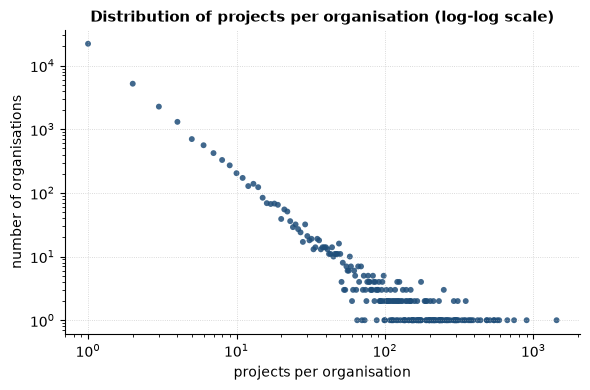

In [7]:
# Distribution of the number of projects per organisation (log-log scale)
counts = projects_per_org.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(counts.index, counts.values, s=18, color="#1f4e79", alpha=0.85, edgecolor="none")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("projects per organisation")
ax.set_ylabel("number of organisations")
ax.set_title("Distribution of projects per organisation (log-log scale)", fontsize=11, fontweight="bold")
ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "projects_per_organisation.png", dpi=200)
plt.show()

Unlike the previous one, this distribution decreases almost linearly on log-log axes. This suggests a heavy-tailed distribution, in which participation is very uneven: most organisations take part in one or a few projects, while a small number take part in hundreds.

### Composition by activity type and country

We describe who takes part in the programme: the type of organisation (university, research centre, company, public body, other) and the country. We first check that name, country and activity type are the same in all the participations of an organisation. We then keep one row per organisation, so that each organisation is counted once regardless of how many projects it takes part in.

In [8]:
# Number of organisations whose name, country or activity type differ across their participations
varying = participations.groupby("organisationID")[["name", "country", "activityType"]].nunique().gt(1).sum()
print("Organisations with more than one value across their participations:")
print(varying.to_string())

# Keep the first row of each organisation, so that every organisation is counted once
organisations = participations.drop_duplicates("organisationID")

# Activity type: HES = higher education, REC = research centre, PRC = private company, PUB = public body, OTH = other
print("\nOrganisations by activity type:")
print(organisations["activityType"].value_counts(dropna=False).to_string())

print("\nOrganisations by country (top 10):")
print(organisations["country"].value_counts().head(10).to_string())

Organisations with more than one value across their participations:
name            0
country         0
activityType    0

Organisations by activity type:
activityType
PRC    20366
OTH     5347
REC     3544
PUB     3033
HES     2909
NaN        1

Organisations by country (top 10):
country
DE    3608
ES    3371
FR    2965
IT    2858
NL    1951
UK    1723
BE    1654
EL    1219
PT     962
AT     937


No organisation has more than one name, country or activity type across its participations, so its first row describes it correctly. Private companies are 58% of the organisations (20,366), while universities and research centres together are 18%. Germany, Spain, France and Italy host 36% of the organisations, and one non-EU country, the United Kingdom (6th), is among the ten most represented.

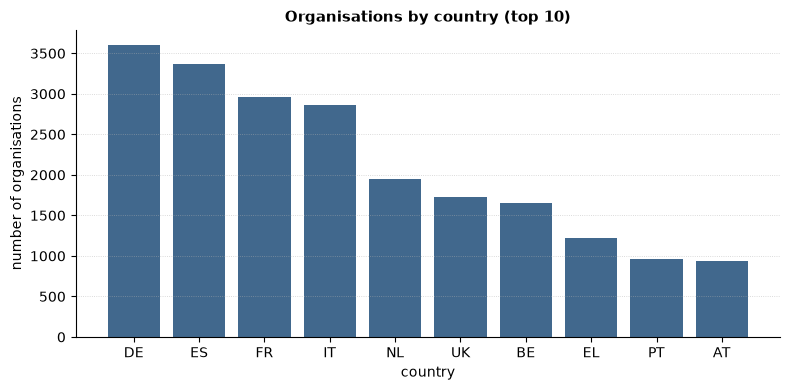

In [9]:
# Number of organisations in the 10 most represented countries
top_countries = organisations["country"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(top_countries.index, top_countries.values, color="#1f4e79", alpha=0.85)
ax.set_xlabel("country")
ax.set_ylabel("number of organisations")
ax.set_title("Organisations by country (top 10)", fontsize=11, fontweight="bold")
ax.grid(True, axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "organisations_by_country.png", dpi=200)
plt.show()

### Participation roles

CORDIS records each participation with one of four roles: coordinator, participant, associated partner (a member of the consortium that receives no EU funding) and third party (an entity linked to a beneficiary that carries out part of the work). We count how many participations fall under each role.

In [10]:
# Number of participations by role
print("Participations by role:")
print(participations["role"].value_counts().to_string())

Participations by role:
role
participant          91019
associatedPartner    24828
coordinator          23609
thirdParty            6175


Coordinators and participants, the beneficiaries of the grants, account for 79% of the participations (23,609 and 91,019 out of 145,631). The other two roles account for the remaining 21%: 24,828 associated partners and 6,175 third parties. All four are treated as participations and generate edges (see *Construction rules*).

### Projects per start year

We count how many projects start in each year, to see which years the data cover well. Horizon Europe runs from 2021 to 2027, and a project enters CORDIS only after its grant agreement is signed, so the most recent years may still be incomplete.

In [11]:
# Number of projects starting in each year
projects_by_year = projects["startYear"].value_counts().sort_index()

print("Projects by start year:")
print(projects_by_year.to_string())

Projects by start year:
startYear
2021      30
2022    3344
2023    5130
2024    4959
2025    4468
2026    4750
2027     932


The data contain between 3,300 and 5,100 projects per year from 2022 to 2026, and only 30 for 2021. The 932 projects of 2027 are grants already signed that have not started yet at the snapshot date, so the count for the most recent years is partial and is expected to grow in later releases of the dump.

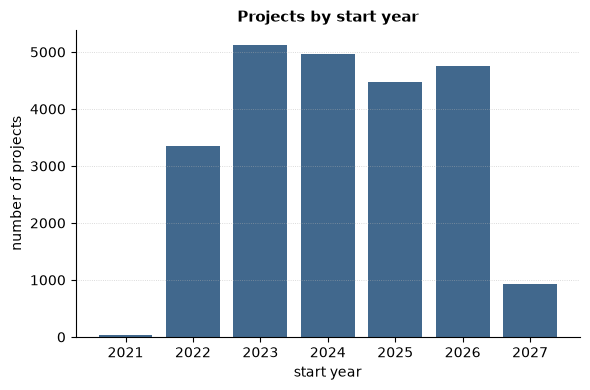

In [12]:
# Bar chart of the number of projects per start year
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(projects_by_year.index.astype(str), projects_by_year.values, color="#1f4e79", alpha=0.85)
ax.set_xlabel("start year")
ax.set_ylabel("number of projects")
ax.set_title("Projects by start year", fontsize=11, fontweight="bold")
ax.grid(True, axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "projects_by_start_year.png", dpi=200)
plt.show()

### Completeness of the attributes

We count the missing values of the three descriptive attributes that will be attached to the nodes. An attribute with many missing values cannot support the analyses that depend on it, so this check tells us in advance whether they can be used in subsequent tasks.

In [13]:
# Number of organisations with a missing value, for each descriptive attribute
org_attributes = ["name", "country", "activityType"]
print("Organisations with a missing value:")
print(organisations[org_attributes].isna().sum().to_string())

Organisations with a missing value:
name            0
country         5
activityType    1


The three attributes are virtually complete: out of 35,200 organisations, none lacks the name, 5 lack the country and 1 the activity type. They can therefore be used on virtually the whole network.

## Building the network

The network is built in two steps: the edge table, obtained by pairing the participants of every project, and the node table, with the attributes of every organisation. The analysis of the resulting network is left to the next notebooks. Here we only check that the construction is consistent with the characterization above.

### Edges

For every project, every pair of participants becomes an edge. A pair that appears in several projects gives a single edge, whose `weight` is the number of shared projects.

In [14]:
# Go through the projects one by one and count, for every pair of participants, the projects they share
edge_weight = {}
for project_id, group in participations.groupby("projectID"):
    orgs = sorted(group["organisationID"].unique())

    # For every pair of participants of this project: create the edge if the pair is new, otherwise increase its weight
    for a, b in combinations(orgs, 2):
        edge_weight[(a, b)] = edge_weight.get((a, b), 0) + 1

# Turn the dictionary into the edge table: one row per pair of linked organisations, with the number of shared projects (weight)
edges = pd.DataFrame(
    [(a, b, weight) for (a, b), weight in edge_weight.items()],
    columns=["source", "target", "weight"],
)

print("Edges")
print(f"  distinct edges:                 {len(edges):>8}")
print(f"  sum of the weights:             {edges['weight'].sum():>8}")
print(f"  edges with weight > 1:          {(edges['weight'] > 1).sum():>8}  ({(edges['weight'] > 1).mean():.1%})")
print(f"  maximum weight:                 {edges['weight'].max():>8}")

Edges
  distinct edges:                  1061382
  sum of the weights:              1335249
  edges with weight > 1:            132549  (12.5%)
  maximum weight:                      126


The sum of the weights (1,335,249) equals the number of pairs generated by the projects in the characterization, so the construction is consistent. These pairs collapse into 1,061,382 distinct edges: 87.5% link organisations that share a single project, and 12.5% organisations that share more than one, up to 126.

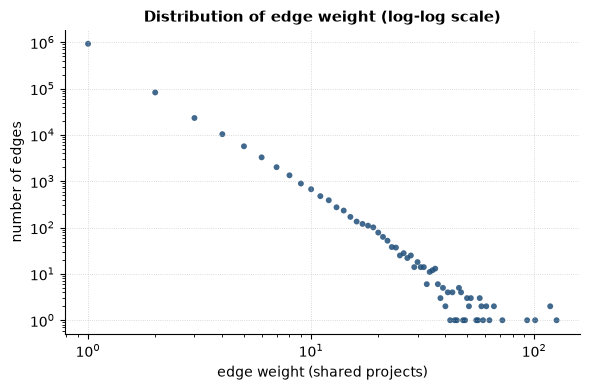

In [15]:
# Distribution of edge weight (log-log scale)
counts = edges["weight"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(counts.index, counts.values, s=18, color="#1f4e79", alpha=0.85, edgecolor="none")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("edge weight (shared projects)")
ax.set_ylabel("number of edges")
ax.set_title("Distribution of edge weight (log-log scale)", fontsize=11, fontweight="bold")
ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "edge_weight_distribution.png", dpi=200)
plt.show()

On log-log axes the distribution is close to a straight line with a steep slope: the number of edges falls by roughly three orders of magnitude for every order of magnitude of weight.

### Nodes

Every organisation becomes a node, with one row in the node table. Name, country and activity type are read from one of its participations, since they are the same in all of them. The number of projects and the number of projects coordinated are counted over all its participations. The last node attribute, `isolated`, is computed from the edge table built above: it is true for the organisations that appear in no edge.

In [16]:
# Descriptive attributes of the organisation: one row per organisation, since they are the same in all its participations
descriptive = organisations[["organisationID", "name", "country", "activityType"]]

# Activity attributes of the organisation: one value per organisation, computed over all its participations
activity = participations.groupby("organisationID").agg(
    n_projects=("projectID", "nunique"),       # number of projects
    n_coordinated=("is_coordinator", "sum"),   # number of projects coordinated
).reset_index()

# Join the two groups of attributes into the node table, one row per organisation, sorted by identifier
nodes = descriptive.merge(activity, on="organisationID").rename(columns={"organisationID": "id"})
nodes = nodes.sort_values("id").reset_index(drop=True)

# Flag the organisations that appear in no edge (all their projects have a single participant)
linked = set(edges["source"]) | set(edges["target"])
nodes["isolated"] = ~nodes["id"].isin(linked)

print("Nodes:")
print(f"  organisations:                  {len(nodes):>8}")
print(f"  isolated (no edge):             {nodes['isolated'].sum():>8}  ({nodes['isolated'].mean():.1%})")
nodes.head()

Nodes:
  organisations:                     35200
  isolated (no edge):                  818  (2.3%)


,id,name,country,activityType,n_projects,n_coordinated,isolated
0,863062933,TOWNROCK ENERGY LIMITED,UK,PRC,1,0,False
1,863072633,HUMANETICS EUROPE GMBH,DE,PRC,1,0,False
2,863292920,SMART FARM ROBOTIKS,BG,PRC,1,1,True
3,863379735,AKCES NCBR SPOLKA Z OGRANICZONA ODPOWIEDZIALNO...,PL,PRC,1,0,False
4,863433667,City of Cape Town,ZA,PUB,1,0,False


Only 818 organisations (2.3%) are isolated, although 46.9% of the projects have a single participant (see *Participants per project*). This is because an organisation with a single-participant project is not necessarily isolated: it is isolated only when all its projects are of this kind.

## Network overview

We assemble the graph with `networkx` and report its basic size and connectivity. The analysis required by Part 2 (degree distribution, components, paths, clustering, centrality, comparison with random models) is carried out in `03_network_analysis.ipynb`.

In [17]:
# Graph with all organisations as nodes, including the isolated ones, and weighted edges
G = nx.Graph()
G.add_nodes_from(nodes["id"])
G.add_weighted_edges_from(edges[["source", "target", "weight"]].itertuples(index=False, name=None))

# Largest connected component
giant = max(nx.connected_components(G), key=len)

print("Network overview")
print(f"  nodes:                          {G.number_of_nodes():>8}")
print(f"  edges:                          {G.number_of_edges():>8}")
print(f"  isolated nodes:                 {nx.number_of_isolates(G):>8}")
print(f"  connected components:           {nx.number_connected_components(G):>8}")
print(f"  largest component:              {len(giant):>8}  ({len(giant) / G.number_of_nodes():.1%} of the nodes)")
print(f"  average degree:                 {2 * G.number_of_edges() / G.number_of_nodes():>8.1f}")
print(f"  density:                        {nx.density(G):>8.5f}")

Network overview
  nodes:                             35200
  edges:                           1061382
  isolated nodes:                      818
  connected components:                864
  largest component:                 34271  (97.4% of the nodes)
  average degree:                     60.3
  density:                         0.00171


The network has 35,200 nodes and 1,061,382 edges. Besides the 818 isolated nodes, it consists of one giant component with 97.4% of the nodes and 45 small components. The average degree is 60 (density 0.0017), which reflects how the network is built: every project links all its participants to each other, and the 1% of projects with most participants generate 30% of the pairs (see *Participants per project*).

## Saving the network

The network is saved as two compressed CSV files in `data/network/`: `nodes.csv.gz` (one row per organisation, with its attributes) and `edges.csv.gz` (one row per pair of linked organisations, with `weight`). The cleaned participations are saved in `data/participations/` as `participations.csv.gz` (one row per organisation–project pair): `04_open_question.ipynb` uses them to build its null model.

In [18]:
# Save the node and edge tables, compressed
nodes.to_csv(NET_DIR / "nodes.csv.gz", index=False, compression="gzip")
edges.to_csv(NET_DIR / "edges.csv.gz", index=False, compression="gzip")

# Save the cleaned participations, one row per organisation-project pair, used in 04_open_question.ipynb
participations[["projectID", "organisationID"]].to_csv(PART_DIR / "participations.csv.gz", index=False, compression="gzip")